In [1]:
from anemone.forwards import Forward
from anemone.experiment import Loop, Receiver, Waveform, ButterworthFilter
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
from scipy.signal import butter, lfilter
from scipy import signal

In [3]:
class ButterworthFilter1:
    def __init__(self, fcut, order=1):
        self.fcut = fcut
        self.order = order

    def omega_filter(self, omega):
        return 1.0 / torch.sqrt((1.0 + (omega / (2.*np.pi*self.fcut)) ** (2 * self.order)))
    
    def __call__(self, f):
        return self.omega_filter(2.*np.pi*f)

class ButterworthFilter:
    def __init__(self, fcut, order=1):
        self.fcut = fcut
        self.order = order

    def omega_filter(self, omega):
        return self.__call__(omega/c.twopi)
    
    def __call__(self, f):
        s = 1j*f/self.fcut
        if   self.order==1: recip_resp = (s+1)
        elif self.order==2: recip_resp = (s**2 + s*2**(1/2) + 1)
        elif self.order==3: recip_resp = (s**2 + s + 1)*(1+s)
        elif self.order==4: recip_resp = (s**2 + 1.84776*s+1)*(s**2 + 0.76537*s+1)
        return 1./torch.sqrt(recip_resp)

c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


(-0.1, 1.1)

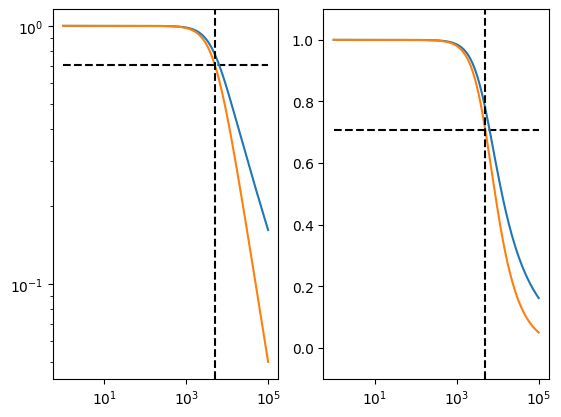

In [4]:
f = torch.logspace(0, 5, 1001, dtype=torch.double)
fig,axs = plt.subplots(1,2)
axs[0].loglog(f, torch.ones_like(f)/np.sqrt(2), 'k--')
axs[1].plot(f, torch.ones_like(f)/np.sqrt(2), 'k--')

bf0 = ButterworthFilter(5e3)
bf1 = ButterworthFilter1(5e3)

axs[0].loglog(f, bf0(f).numpy())
axs[0].loglog(f, bf1(f).numpy())
axs[1].plot(f, bf0(f).numpy())
axs[1].plot(f, bf1(f).numpy())


# axs[1].plot(f, res.imag, f'C{i}--')


ylim = axs[0].get_ylim()
axs[0].loglog([5e3, 5e3], ylim, 'k--')
axs[1].plot([5e3, 5e3], [-0.1, 1.1], 'k--')
axs[0].set_ylim(ylim)
axs[1].set_xscale('log')
axs[1].set_ylim(-0.1, 1.1)

In [5]:
class Hfunc:
    def __init__(self, b,a):
        self.b = b
        self.a = a

    def __call__(self, f):
        return torch.tensor(np.polyval(self.b, 1j*f)/np.polyval(self.a, 1j*f))#real
    
    def omega_filter(self, omega):
        return self.__call__(0.5*omega/np.pi)

(-0.1, 1.1)

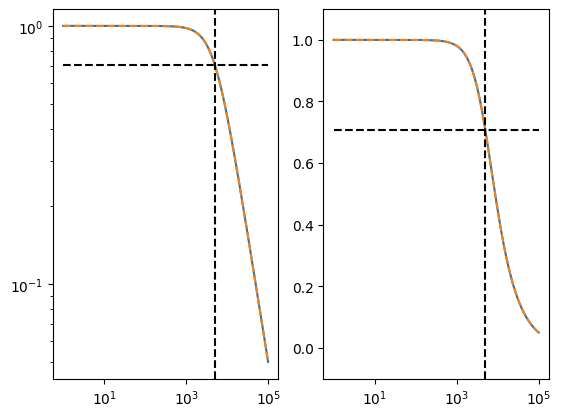

In [6]:
fs = 1e6
fcut = 5e3
b, a = signal.butter(1, fcut, output='ba', analog=True)
w, h = signal.freqs(b, a)





f = torch.logspace(0, 5, 1001, dtype=torch.double)
fig,axs = plt.subplots(1,2)
axs[0].loglog(f, torch.ones_like(f)/np.sqrt(2), 'k--')
axs[1].plot(f, torch.ones_like(f)/np.sqrt(2), 'k--')

bf0 = ButterworthFilter1(fcut)
#bf1 = Hfunc(b[::-1],a[::-1])
bf1 = Hfunc(b,a)

H = abs(bf1(f))
#H = b[0] / (a[1] + a[0]*1j*f)


axs[0].loglog(f, bf0(f).numpy())
axs[0].loglog(f, H, '--')
# axs[0].loglog(w, abs(h), 'r--')

axs[1].plot(f, bf0(f).numpy())
axs[1].plot(f, H, '--')
# axs[1].plot(w, abs(h), 'r--')


# axs[1].plot(f, res.imag, f'C{i}--')


ylim = axs[0].get_ylim()
axs[0].loglog([fcut, fcut], ylim, 'k--')
axs[1].plot([fcut, fcut], [-0.1, 1.1], 'k--')
axs[0].set_ylim(ylim)
axs[1].set_xscale('log')
axs[1].set_ylim(-0.1, 1.1)

(-0.1, 1.1)

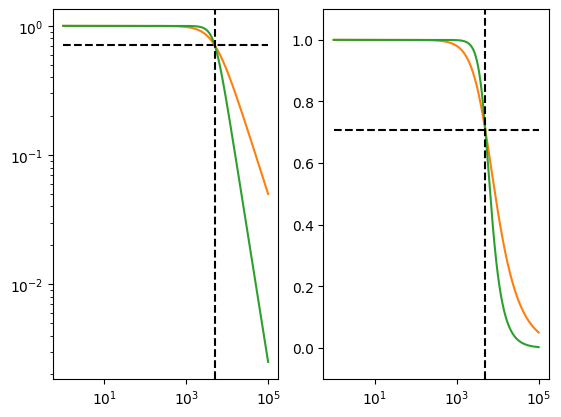

In [473]:
f = torch.logspace(0, 5, 1001, dtype=torch.double)
fig,axs = plt.subplots(1,2)
axs[0].loglog(f, torch.ones_like(f)/np.sqrt(2), 'k--')
axs[1].plot(f, torch.ones_like(f)/np.sqrt(2), 'k--')
for i in range(1, 3):
    bf1 = ButterworthFilter1(5e3, i)
    res = bf1(f)
    axs[0].loglog(f, np.abs(res), f'C{i}-')
    axs[1].plot(f, res.real, f'C{i}-')
    # axs[1].plot(f, res.imag, f'C{i}--')


ylim = axs[0].get_ylim()
axs[0].loglog([5e3, 5e3], ylim, 'k--')
axs[1].plot([5e3, 5e3], [-0.1, 1.1], 'k--')
axs[0].set_ylim(ylim)
axs[1].set_xscale('log')
axs[1].set_ylim(-0.1, 1.1)

In [474]:
tx = Loop.square(3)
rx = Receiver(x=10.)
t = torch.logspace(-6, -3, 52)

w, h = signal.freqs(b, a)


fcut = 1e4


bf1 = ButterworthFilter1(fcut, order=1)
b, a = signal.butter(1, fcut, output='ba', analog=True)
bf2 = Hfunc(b,a)

fwr0 = Forward(tx, rx, t)
fwr1 = Forward(tx, rx, t, filterfunc=bf1)
fwr2 = Forward(tx, rx, t, filterfunc=bf2)

In [475]:
from anemone.experiment import FilterChain

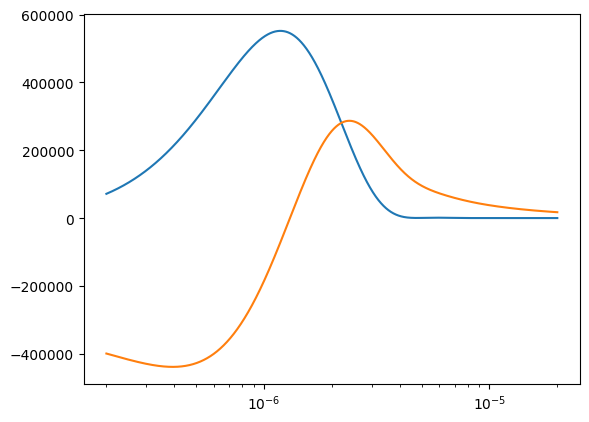

In [593]:
#from anemone.transforms import invFourier


fcut = 210e3
b, a = signal.butter(1, fcut, output='ba', analog=True)
bf_210 = Hfunc(b,a)

fcut = 300e3
b, a = signal.butter(2, fcut, output='ba', analog=True)
bf_300 = Hfunc(b,a)

bf2 = FilterChain([bf_210, bf_300])



bf = ButterworthFilter(300e3, order=1)
# bf2 = ButterworthFilter(210e3, order=4)


#t_t = torch.logspace(-8, -5, 1001, dtype=torch.double)
t_t = torch.linspace(2e-7, 2e-5, 50001, dtype=torch.double)

h_t = invFourier(bf, range=(t_t.min(), t_t.max()))
h = h_t(t_t)

fig,axs = plt.subplots(1,1)
# axs.plot(t_t, h.real.numpy())

h_t = invFourier(bf2, range=(t_t.min(), t_t.max()))
h = h_t(t_t)

axs.semilogx(t_t, h.real.numpy())
axs.semilogx(t_t, h.imag.numpy())

In [594]:
class TDfilter:
    def __init__(self, time, taps):
        self.time = time
        self.taps = taps

from anemone.experiment import lamontagne

def wv_to_t(t_eval, t_sampled, td_filt=None):
    t_eval = t_eval.to(torch.double)
    t_sampled = t_sampled.to(torch.double)

    logT = torch.log(t_sampled)#.cpu()
    dT = logT[1]-logT[0]

    t2t = torch.zeros(t_eval.shape+t_sampled.shape, device=t_sampled.device, dtype=torch.complex128)

    for t_wv,k_wv in zip(td_filt.time, td_filt.taps):
        t2t += k_wv*torch.nan_to_num(lamontagne((torch.log(t_eval-t_wv)[:,None]-logT[None,:])/dT))
    return t2t

In [595]:
t = torch.logspace(-9, -3, 101)*2
rho = torch.tensor([40, 80,50])
thickness = torch.tensor([10, 20])*2

In [596]:
# from anemone.forwards import *
from anemone.experiment import Waveform

In [597]:
wv = Waveform.example()
fwr0 = ForwardGeomOp(tx, rx, t)
fwr1 = ForwardGeomOp(tx, rx, t, filterfunc=bf2)
dbdt0 = fwr0(rho, thickness).squeeze()
dbdt1 = fwr1(rho, thickness).squeeze()


In [598]:
t_out = torch.logspace(-6, -3, 51)
t2t = wv_to_t(t_out, t, TDfilter(t_t, h)).real*(t_t[1]-t_t[0])

<Figure size 640x480 with 0 Axes>

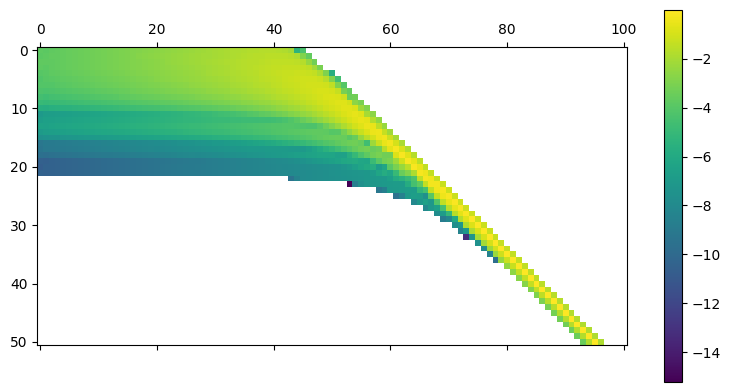

In [599]:
plt.figure()
pcm=plt.matshow(torch.log10(abs(t2t)))
plt.colorbar(pcm)

In [600]:
dbdt2 = (t2t@dbdt0)

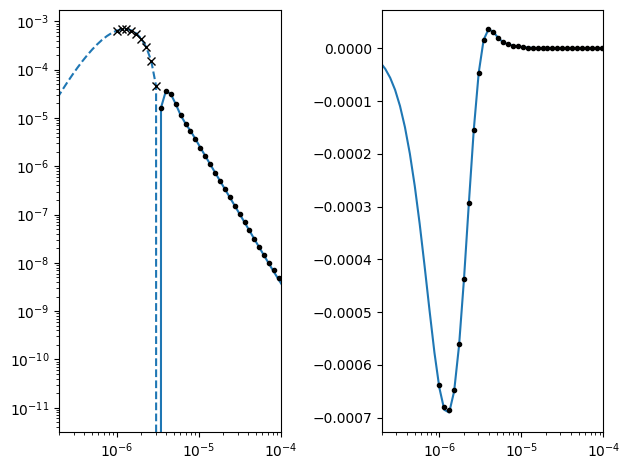

In [601]:

fig,axs = plt.subplots(1,2, sharex=True)

# axs[0].loglog(t, dbdt0.real.numpy(), 'C2')
# axs[0].loglog(t, -dbdt0.real.numpy(), 'C2--')
axs[0].loglog(t, dbdt1.real.numpy())
axs[0].loglog(t, -dbdt1.real.numpy(), 'C0--')
axs[0].loglog(t_out, dbdt2.real.numpy(), 'k.')
axs[0].loglog(t_out, -dbdt2.real.numpy(), 'kx')

axs[1].semilogx(t, dbdt1.real.numpy())
axs[1].semilogx(t_out[dbdt2.real>0], dbdt2.real.numpy()[dbdt2.real>0], 'k.')
axs[1].semilogx(t_out[dbdt2.real<0], dbdt2.real.numpy()[dbdt2.real<0], 'kx')


plt.xlim(2e-7, 1e-4)
plt.tight_layout()


In [ ]:
from anemone.experiment import lamontagne

def wv_to_t(t_eval, t_sampled, waveform=None):
    t_eval = t_eval.to(torch.double)
    t_sampled = t_sampled.to(torch.double)

    logT = torch.log(t_sampled)#.cpu()
    dT = logT[1]-logT[0]
    if waveform is None:
        t2t = lamontagne((torch.log(t_eval)[:,None]-logT[None,:])/dT)
    else:
        t2t = torch.zeros(t_eval.shape+t_sampled.shape, device=t_sampled.device, dtype=t_eval.dtype)

        for t_wv,k_wv in zip(waveform.time, waveform.d2wdt2):
            t2t += k_wv*lamontagne((torch.log(t_eval-t_wv)[:,None]-logT[None,:])/dT)
    return t2t

In [58]:
rho = torch.tensor([40, 80,50])
thickness = torch.tensor([10, 20])*2

dbdt0 = fwr0(rho, thickness)
dbdt1 = fwr1(rho, thickness)
dbdt2 = fwr2(rho, thickness)

In [31]:
from scipy.signal import butter, lfilter

In [32]:
from anemone.experiment import lamontagne


def intMat(t_in, t_out):
    t_out = t_out.to(t_in.dtype)
    logT = torch.log(t_in)#.cpu()
    dT = logT[1]-logT[0]
    t2t = torch.nan_to_num(lamontagne((torch.log(t_out)[:,None]-logT[None,:])/dT))
    return t2t

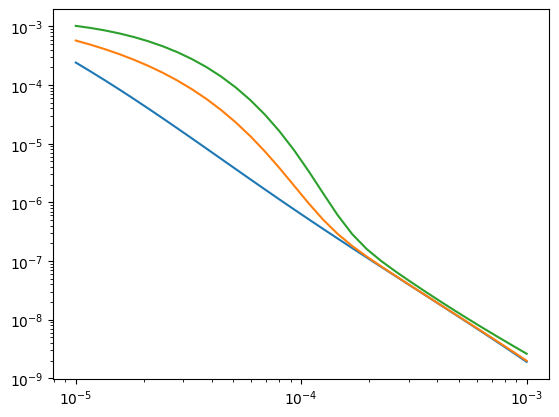

In [33]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.loglog(t, dbdt0.numpy())
plt.loglog(t, dbdt1.numpy())
plt.loglog(t, dbdt2.numpy())

In [25]:
from numpy import convolve
def my_filtfilt(b, a, x):
    ab = b
    ab[:-1] += -a[1:]
    y1 = convolve(x, ab, mode='full')
    return y1[len(b)-1:]#*a[1]

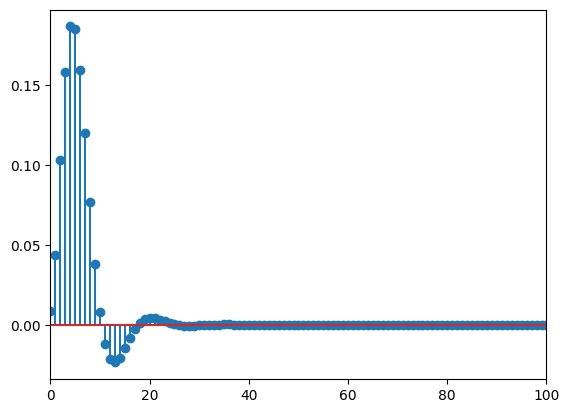

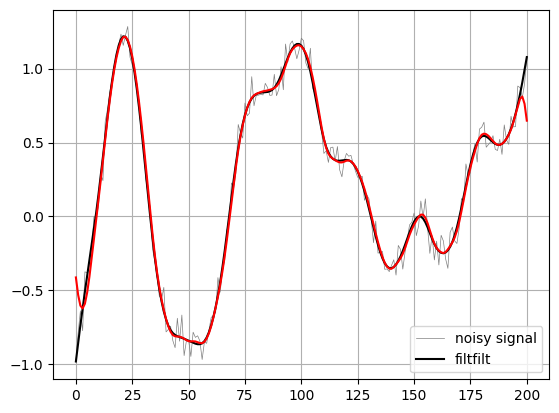

In [26]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
rng = np.random.default_rng()
t = np.linspace(-1, 1, 201)
t2 = t#[:-1]
x = (np.sin(2*np.pi*0.75*t*(1-t) + 2.1) +
     0.1*np.sin(2*np.pi*1.25*t + 1) +
     0.18*np.cos(2*np.pi*3.85*t))
xn = x + rng.standard_normal(len(t)) * 0.08

b, a = signal.butter(3, 0.15, output='ba')

X = np.fft.rfft(xn)

w,H = signal.freqz(b, a)

frq,X = np.fft.rfftfreq(len(xn), d=t[1]-t[0]), np.fft.rfft(xn)



h = np.fft.irfft(H)

#c,A,pk = signal.residuez(b, a)

#t,h = signal.impulse((b, a))


y2 = np.convolve(xn, h, mode='full')[len(b):]
y2 = y2[:len(xn)]    
#[len(b)//2:-len(b)//2+1]
# y2 /= y2.max()



plt.figure()
plt.stem(h)
plt.xlim(0, 100)

y = signal.filtfilt(b, a, xn)
# y2 = my_filtfilt(b, a, xn)

# y = y/y.max()

plt.figure()
plt.plot(xn,  'gray', linewidth=0.5)
plt.plot(y, 'k')
plt.plot(y2, 'r')
plt.legend(('noisy signal',  'filtfilt'), loc='best')
plt.grid(True)
plt.show()

<StemContainer object of 3 artists>

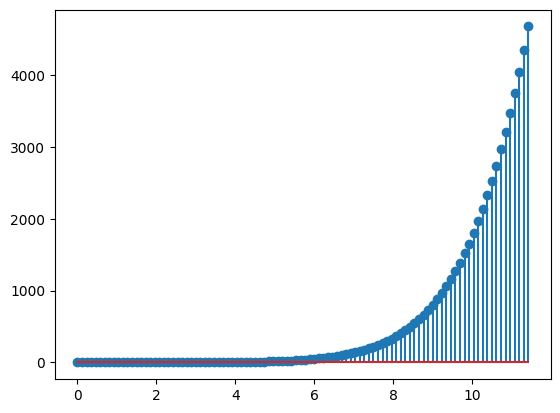

In [27]:
from scipy import signal
#system = ([1.0], [1.0, 2.0, 1.0])
t, y = signal.impulse(signal.butter(5, 0.15, output='ba'))
import matplotlib.pyplot as plt
plt.stem(t, y)

<StemContainer object of 3 artists>

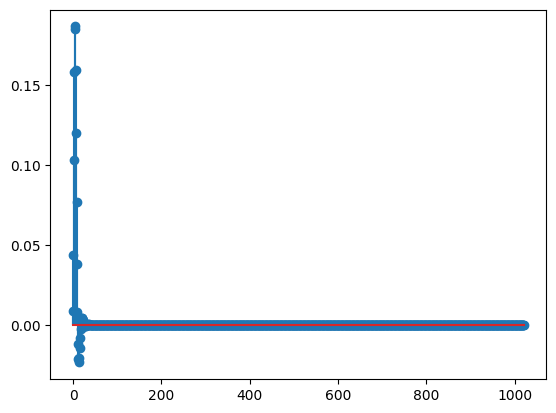

In [28]:
plt.figure()
plt.stem(h)